# MolCLR embeddings

- This notebook generates embeddings across several datasets using the **MolCLR** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [ ]:
import os
import sys
import torch
from rdkit import Chem
from torch_geometric.data import Data
from torch_geometric.data import Data, DataLoader
import numpy as np
import torch.nn.functional as F
import pandas as pd
from tqdm.auto import tqdm
import sklearn 
from sklearn.metrics.pairwise import cosine_similarity

sys.path.append(os.getcwd())
from MolCLR_models.ginet_molclr import GINet

/home/blake/miniconda3/envs/molclr_clean/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''
CHKPT_PATH   = ''

# Model set-up

In [2]:
CHIRALITY_MAP = {
    Chem.rdchem.ChiralType.CHI_UNSPECIFIED: 0,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW: 1,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW: 2,
    Chem.rdchem.ChiralType.CHI_OTHER: 0,
}

BOND_TYPE_MAP = {
    Chem.rdchem.BondType.SINGLE: 0,
    Chem.rdchem.BondType.DOUBLE: 1,
    Chem.rdchem.BondType.TRIPLE: 2,
    Chem.rdchem.BondType.AROMATIC: 3,
}

BOND_DIR_MAP = {
    Chem.rdchem.BondDir.NONE: 0,
    Chem.rdchem.BondDir.ENDUPRIGHT: 1,
    Chem.rdchem.BondDir.ENDDOWNRIGHT: 2,
}


def molclr_data_from_smiles(smiles: str) -> Data:
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    x = []
    for atom in mol.GetAtoms():
        atom_type_idx = atom.GetAtomicNum() - 1
        chirality_idx = CHIRALITY_MAP.get(atom.GetChiralTag(), 0)
        x.append([atom_type_idx, chirality_idx])

    x = torch.tensor(x, dtype=torch.long)

    edge_index = []
    edge_attr = []
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        bond_type_idx = BOND_TYPE_MAP.get(bond.GetBondType(), 0)
        bond_dir_idx = BOND_DIR_MAP.get(bond.GetBondDir(), 0)

        edge_index += [[i, j], [j, i]]
        edge_attr += [[bond_type_idx, bond_dir_idx], [bond_type_idx, bond_dir_idx]]

    if len(edge_index) > 0:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_attr, dtype=torch.long)
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 2), dtype=torch.long)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)


def load_molclr_gin(CHKPT_PATH: str, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = GINet(
        num_layer=5,
        emb_dim=300,
        feat_dim=512,
        drop_ratio=0,
        pool="mean",
    )

    state = torch.load(CHKPT_PATH, map_location="cpu")
    model.load_state_dict(state)
    model.to(device)
    model.eval()
    return model, device


@torch.no_grad()
def embed_smiles_list(smiles_list, model, device, batch_size=64):
    data_list = [molclr_data_from_smiles(s) for s in smiles_list]
    loader = DataLoader(data_list, batch_size=batch_size, shuffle=False)

    all_embeddings = []
    for batch in loader:
        batch = batch.to(device)
        h, out = model(batch)
        all_embeddings.append(h.cpu())

    return torch.cat(all_embeddings, dim=0)

In [ ]:
model, device = load_molclr_gin(CHKPT_PATH)

In [4]:
model, device = load_molclr_gin(CHKPT_PATH)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Non-trainable:        {total_params - trainable_params:,}")

Total parameters:     2,404,196
Trainable parameters: 2,404,196
Non-trainable:        0


# MCES

In [14]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
embeddings = embed_smiles_list(smiles.tolist(), model, device)
np.save('MCES/MolCLR MCES embeddings.npy', embeddings)

In [ ]:
X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/MolCLR pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [02:04<00:00,  1.94s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/MolCLR pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:40<00:00, 1566.88it/s]

Expected: 2012094766
Written: 2012094766


# MCES figure example

We will need to scale the cosine similarities for the sake of generating the MCES example

In [ ]:
def indices(smiles, smi_a, smi_b):
    """ Return the indices of two molecules in a list of SMILES """
    a_idx = -1
    b_idx = -1
    for i, s in enumerate(smiles):
        if s == smi_a:
            a_idx = i
        if s == smi_b:
            b_idx = i
    return a_idx, b_idx

def condensed_index(i, j, n):
    """ Index into the flattened strict upper triangle (row-major) of an n x n matrix."""
    if i > j:
        i, j = j, i  # cosine similarity is symmetric
    return n * i - i * (i + 1) // 2 + (j - i - 1)

def scale(pairwise_cosine, censored, index):
    """
    MolCLR produces extreme cosine similarities for all
    molecules. We therefore scale to cosines for the 
    purpose of the MCES example. Bounds are computed on
    uncensored pairs only. 
    """
    lo, hi = np.percentile(pairwise_cosine[~censored], [1, 99])
    return np.clip((pairwise_cosine[index] - lo) / (hi - lo), 0, 1)


In [ ]:
# Load the molecules that are censored so we only scale by the appropriate molecules 
censored = np.load('censor_mask.npy') 
censored = censored | (distances['mces'] == -1) 

Cosine similarity: 0.9997127812350407


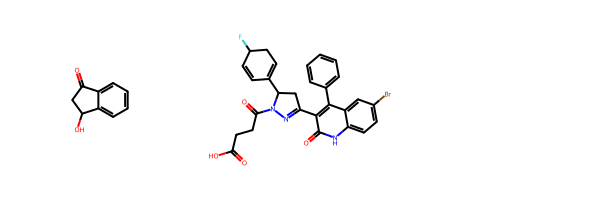

In [40]:
# Locate the correct pairwise cosine for the two pairs
close_pair_a = "C1C(C2=CC=CC=C2C1=O)O"
close_pair_b = "C1C=C(C=CC1F)C2CC(=NN2C(=O)CCC(=O)O)C3=C(C4=C(C=CC(=C4)Br)NC3=O)C5=CC=CC=C5"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

a_idx, b_idx  = indices(smiles, close_pair_a, close_pair_b)
index         = condensed_index(a_idx, b_idx, len(smiles))

print(f"Cosine similarity: {scale(pairwise_cosine, censored, index)}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: 0.4475506621988192


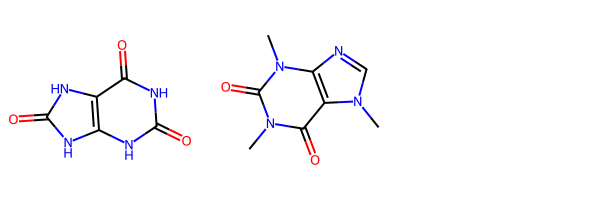

In [41]:
# Locate the correct pairwise cosine for the two pairs
distant_pair_a = "C12=C(NC(=O)N1)NC(=O)NC2=O"
distant_pair_b = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

a_idx, b_idx  = indices(smiles, distant_pair_a, distant_pair_b)
index         = condensed_index(a_idx, b_idx, len(smiles))

print(f"Cosine similarity: {scale(pairwise_cosine, censored, index)}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [ ]:
embeddings = embed_smiles_list(smiles, model, device)
np.save('Biogen/MolCLR Biogen embeddings.npy', embeddings)

# ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [ ]:
embeddings = embed_smiles_list(smiles, model, device)
np.save('ZINC/MolCLR ZINC30K embeddings.npy', embeddings)